In [89]:
# =====================================================================
# 1. IMPORTS + SQL CONNECTION
# =====================================================================
import os
import uuid
import warnings
import urllib.parse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text

# BTYD models from the `lifetimes` package
from lifetimes import ModifiedBetaGeoFitter, BetaGeoFitter, ParetoNBDFitter, GammaGammaFitter
from lifetimes.plotting import plot_period_transactions

warnings.filterwarnings("ignore", category=FutureWarning)   # keep the output readable

# --- Connection settings --------------------------------------------
# The server name is read from an environment variable called SQL_SERVER, so my machine name
# is not hard-coded in the repo. Examples: "localhost" or "localhost\SQLEXPRESS" (named instance).
SERVER_NAME = os.environ.get("SQL_SERVER", "localhost")
DB_NAME = "AdventureWorks2025_CustomerDW"

odbc = (f"DRIVER={{ODBC Driver 17 for SQL Server}};SERVER={SERVER_NAME};"
        f"DATABASE={DB_NAME};Trusted_Connection=yes;")
engine = create_engine("mssql+pyodbc:///?odbc_connect=" + urllib.parse.quote_plus(odbc),
                       fast_executemany=True)   # fast_executemany = faster bulk inserts later

# Every run gets a unique ID so runs can be told apart in the output tables.
run_id = str(uuid.uuid4())
print("run_id:", run_id)

run_id: 782d7e46-7656-41fb-b69f-e730c4209ad5


In [90]:
# =====================================================================
# 2. LOAD BTYD INPUTS FROM THE GOLD LAYER
# =====================================================================
# One row per customer. The SQL already split each history into:
#   - CALIBRATION period -> the models learn from this (frequency, recency, T, monetary_value)
#   - HOLDOUT period     -> the next 90 days, hidden from the models, used only to test them
#
# Definitions:
#   frequency = number of REPEAT purchase days (the first purchase doesn't count)
#   recency   = days between first and last purchase (0 for one-time buyers)
#   T         = days between first purchase and the end of the calibration period
sql = """
SELECT
    customer_key,
    observation_date,
    duration_holdout,
    frequency,
    recency,
    T,
    monetary_value,
    COALESCE(frequency_holdout, 0) AS frequency_holdout
FROM gold.fact_customer_btyd_inputs;
"""
inputs_df = pd.read_sql(sql, engine)

# --- Safety checks: stop early if the input table is wrong -----------
assert inputs_df["customer_key"].is_unique, "Duplicate customers in the inputs table"
assert (inputs_df["T"] > 0).all(), "T must be positive for every customer"
assert (inputs_df["recency"] <= inputs_df["T"]).all(), "recency cannot exceed T"

H = int(inputs_df["duration_holdout"].iloc[0])     # holdout length in days (90)
n_one_time = int((inputs_df["frequency"] == 0).sum())
print(f"Customers: {len(inputs_df):,} | one-time buyers: {n_one_time:,} "
      f"({n_one_time / len(inputs_df):.0%}) | holdout: {H} days")
inputs_df.head()

Customers: 16,300 | one-time buyers: 10,428 (64%) | holdout: 90 days


,customer_key,observation_date,duration_holdout,frequency,recency,T,monetary_value,frequency_holdout
0,20522,2025-06-29,90,2,835,1016,2424.50,0
1,20523,2025-06-29,90,1,732,1020,2419.93,1
2,20524,2025-06-29,90,2,778,1028,2357.03,0
3,20525,2025-06-29,90,2,863,1037,2369.65,0
4,20526,2025-06-29,90,2,829,1012,2398.01,0


               coef      se(coef)  lower 95% bound  upper 95% bound
r      1.370359e+00  4.423223e-02     1.283664e+00     1.457054e+00
alpha  7.567080e+02  2.581825e+01     7.061043e+02     8.073118e+02
a      3.683768e-15  3.730278e-11    -7.310976e-11     7.311713e-11
b      1.235199e-05  1.238346e-01    -2.427034e-01     2.427281e-01


<Figure size 1000x600 with 0 Axes>

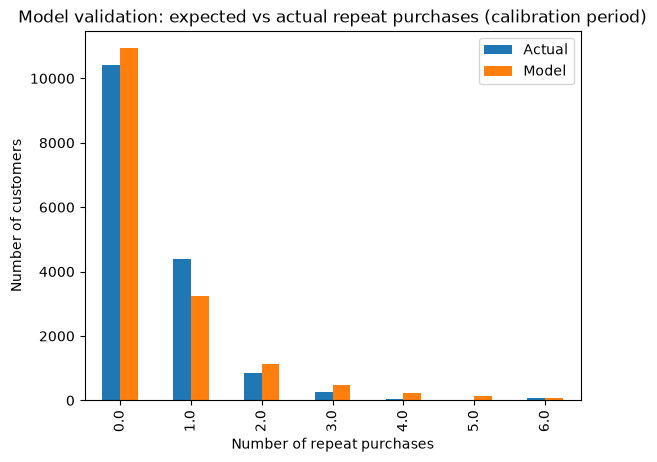

In [91]:
# =====================================================================
# 3. FIT THE PURCHASE-FREQUENCY MODEL (Modified BG/NBD)
# =====================================================================
# The model learns two things:
#   r, alpha -> how often customers buy (their purchase rate)
#   a, b     -> how likely customers are to "die" (stop buying) -> this drives p_alive
# penalizer_coef = a small penalty that keeps the optimizer stable.
mbgf = ModifiedBetaGeoFitter(penalizer_coef=0.001)
mbgf.fit(inputs_df["frequency"], inputs_df["recency"], inputs_df["T"])
print(mbgf.summary)      # coef = estimate, se(coef) = uncertainty. Keep an eye on a and b, I come back to them in step 8.

# --- Calibration plot: expected vs actual repeat purchases -----------
# The bars should be close to each other if the model fits the history well.
plt.figure(figsize=(10, 6))
plot_period_transactions(mbgf)
plt.title("Model validation: expected vs actual repeat purchases (calibration period)")
plt.xlabel("Number of repeat purchases")
plt.ylabel("Number of customers")
plt.show()

Correlation between frequency and order value: 0.428


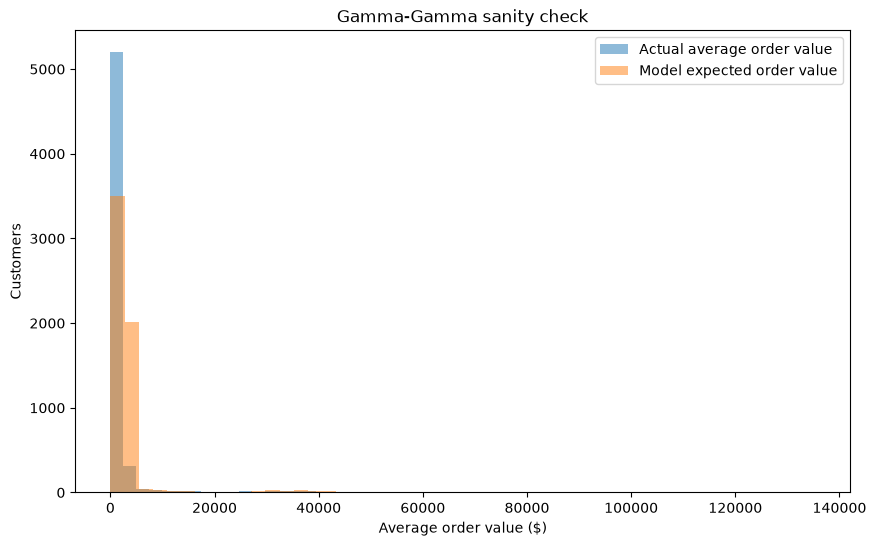

In [92]:
# =====================================================================
# 4. FIT THE SPEND MODEL (Gamma-Gamma)
# =====================================================================
# Only customers with at least one repeat purchase have a measurable average order value.
repeat_spenders = inputs_df[(inputs_df["frequency"] > 0) & (inputs_df["monetary_value"] > 0)].copy()

# Gamma-Gamma assumes frequency and order value are UNRELATED. I check it first:
# a value near 0 means the assumption holds; a large value means be careful.
corr = repeat_spenders[["frequency", "monetary_value"]].corr().iloc[0, 1]
print(f"Correlation between frequency and order value: {corr:.3f}")
# In my run it is 0.428, far from 0, so the assumption is violated here.
# I keep the model but read the order-value and revenue forecasts with caution.

ggf = GammaGammaFitter(penalizer_coef=0.01)
ggf.fit(repeat_spenders["frequency"], repeat_spenders["monetary_value"])

# The model's "shrunk" estimate of each customer's true average order value
expected_monetary = ggf.conditional_expected_average_profit(
    repeat_spenders["frequency"], repeat_spenders["monetary_value"]
)

# Sanity check: the two distributions should look broadly similar
plt.figure(figsize=(10, 6))
plt.hist(repeat_spenders["monetary_value"], bins=50, alpha=0.5, label="Actual average order value")
plt.hist(expected_monetary, bins=50, alpha=0.5, label="Model expected order value")
plt.title("Gamma-Gamma sanity check")
plt.xlabel("Average order value ($)")
plt.ylabel("Customers")
plt.legend()
plt.show()

In [93]:
# =====================================================================
# 5. HOLDOUT VALIDATION: how well does the model predict the unseen 90 days?
# =====================================================================
# Expected number of purchases for each customer over the holdout window
inputs_df["predicted_holdout_purchases"] = mbgf.conditional_expected_number_of_purchases_up_to_time(
    H, inputs_df["frequency"], inputs_df["recency"], inputs_df["T"]
)
y = inputs_df["frequency_holdout"]               # what really happened
p = inputs_df["predicted_holdout_purchases"]     # what the model expected
inputs_df["bought_in_holdout"] = y > 0           # used again in steps 12 and 13

# --- Totals + simple baselines ---------------------------------------
# Most customers buy NOTHING in 90 days, so a "predict zero" guess is a strong baseline.
metrics = {
    "actual_purchases":     int(y.sum()),
    "predicted_purchases":  round(float(p.sum()), 1),
    "volume_error_pct":     round(100 * (p.sum() - y.sum()) / y.sum(), 2),
    "mae_model":            round(float((y - p).abs().mean()), 4),
    "mae_predict_zero":     round(float(y.abs().mean()), 4),              # baseline 1: nobody buys
    "mae_predict_average":  round(float((y - y.mean()).abs().mean()), 4), # baseline 2: everyone average
    "rank_correlation":     round(float(y.corr(p, method="spearman")), 3),
}
for k, v in metrics.items():
    print(f"{k:22s}: {v}")

# --- Lift table: sort customers by prediction, cut into 10 equal groups ---
# If the model ranks customers well, the "actual" column should rise from group 1 to 10.
inputs_df["pred_decile"] = pd.qcut(p.rank(method="first"), 10, labels=False) + 1
lift = inputs_df.groupby("pred_decile").agg(
    customers=("customer_key", "count"),
    predicted=("predicted_holdout_purchases", "mean"),
    actual=("frequency_holdout", "mean"),
).round(3)
print(lift)
# The total looks good (+7%), but the lift table does not: decile 1 (lowest predicted) has the
# HIGHEST actual rate, and the rank correlation is negative. I look into both below.

actual_purchases      : 2475
predicted_purchases   : 2654.6
volume_error_pct      : 7.26
mae_model             : 0.2667
mae_predict_zero      : 0.1518
mae_predict_average   : 0.2619
rank_correlation      : -0.135
             customers  predicted  actual
pred_decile                              
1                 1630      0.094   0.566
2                 1630      0.122   0.087
3                 1630      0.128   0.061
4                 1630      0.134   0.079
5                 1630      0.141   0.074
6                 1630      0.147   0.066
7                 1630      0.155   0.071
8                 1630      0.165   0.108
9                 1630      0.199   0.101
10                1630      0.343   0.307


In [94]:
# =====================================================================
# 6. FAIR BASELINES: does the model beat simple rules that use ONLY calibration data?
# =====================================================================
# (My earlier baselines used holdout averages, which the model could never see. These don't.)
# Baseline 1: everyone buys at the overall historical rate.
const_rate = inputs_df["frequency"].sum() / inputs_df["T"].sum() * H
inputs_df["pred_constant"] = const_rate
# Baseline 2: each customer keeps their own historical repeat rate.
inputs_df["pred_naive_rate"] = inputs_df["frequency"] / inputs_df["T"] * H

rows = {}
for name, col in [("MBG/NBD model", "predicted_holdout_purchases"),
                  ("Own historical rate", "pred_naive_rate"),
                  ("Same rate for everyone", "pred_constant")]:
    pr = inputs_df[col]
    rows[name] = {
        "volume_error_%": round(100 * (pr.sum() - y.sum()) / y.sum(), 1),
        "MAE": round(float((y - pr).abs().mean()), 4),
        "rank_corr": round(float(y.corr(pr, method="spearman")), 3) if pr.nunique() > 1 else np.nan,
    }
baselines = pd.DataFrame(rows).T
print(baselines)
# Read it plainly: the simple rules do as well as the model on the total, and
# "own historical rate" has a lower per-customer error. So the +7% total is not proof of skill.

                        volume_error_%     MAE  rank_corr
MBG/NBD model                      7.3  0.2667     -0.135
Own historical rate              -10.2  0.2319      0.003
Same rate for everyone             9.3  0.2722        NaN


In [95]:
# =====================================================================
# 7. p_alive (probability a customer is still active)
# =====================================================================
# The total looked fine in step 5, but the baselines in step 6 showed it isn't real skill.
# So I check the other thing BTYD models promise: a probability for each customer.
p_alive_raw = mbgf.conditional_probability_alive(
    inputs_df["frequency"], inputs_df["recency"], inputs_df["T"]
)
print(pd.Series(p_alive_raw).describe())
# Expected: values spread between 0 and 1.
# What I got: exactly 1.0 for all 16,300 customers (std ~ 1e-10).

count    1.630000e+04
mean     1.000000e+00
std      2.266927e-10
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64


In [96]:
# =====================================================================
# 8. DIAGNOSIS STEP 1: look at the dropout parameters a and b
# =====================================================================
# In BG/NBD, a and b control dropout. If both collapse to ~0, the model is saying
# "customers never leave", and p_alive becomes 1.0 for everybody.
print(mbgf.summary)
print(f"\na = {mbgf.params_['a']:.2e}   b = {mbgf.params_['b']:.2e}")
# In my run: a ~ 3.7e-15, b ~ 1.2e-05, and the standard errors are bigger than the estimates
# (the confidence intervals even include negative numbers), so the model has no real estimate of dropout.

               coef      se(coef)  lower 95% bound  upper 95% bound
r      1.370359e+00  4.423223e-02     1.283664e+00     1.457054e+00
alpha  7.567080e+02  2.581825e+01     7.061043e+02     8.073118e+02
a      3.683768e-15  3.730278e-11    -7.310976e-11     7.311713e-11
b      1.235199e-05  1.238346e-01    -2.427034e-01     2.427281e-01

a = 3.68e-15   b = 1.24e-05


In [97]:
# =====================================================================
# 9. ATTEMPTS TO "FIX" THE MODEL (all failed in my run, and that's the finding)
# =====================================================================

# ---- Attempt A: standard BG/NBD with a bigger penalizer ----
# NOTE: I first passed fit_method='L-BFGS-B', but that is NOT a real option in lifetimes.
# It was silently ignored (I saw "OptimizeWarning: Unknown solver options"), so it tested
# nothing new and I removed it.
try:
    bgf_a = BetaGeoFitter(penalizer_coef=0.01)
    bgf_a.fit(inputs_df["frequency"], inputs_df["recency"], inputs_df["T"])
    print("A) BG/NBD, days:\n", bgf_a.params_, "\n")
except Exception as e:
    print("A) failed:", type(e).__name__, "\n")

A) BG/NBD, days:
 r        9.732628e-01
alpha    5.337420e+02
a        5.112246e-22
b        5.872187e-13
dtype: float64 



In [98]:
# ---- Attempt B: change the time unit from days to weeks ----
# Idea: smaller numbers might help the optimizer.
inputs_df["recency_weeks"] = inputs_df["recency"] / 7
inputs_df["T_weeks"] = inputs_df["T"] / 7
try:
    bgf_b = BetaGeoFitter(penalizer_coef=0.05)
    bgf_b.fit(inputs_df["frequency"], inputs_df["recency_weeks"], inputs_df["T_weeks"])
    print("B) BG/NBD, weeks:\n", bgf_b.params_, "\n")
except Exception as e:
    print("B) failed:", type(e).__name__, "(ConvergenceError in my run)\n")

  message: Desired error not necessarily achieved due to precision loss.
  success: False
   status: 2
      fun: 0.1869210912551488
        x: [-4.354e-01 -1.091e+00 -2.223e+01 -1.761e+01]
      nit: 66
      jac: [ 1.107e-07 -1.455e-07 -6.827e-11  7.419e-11]
 hess_inv: [[ 3.635e+00  3.224e+00 -2.662e+04 -2.654e+04]
            [ 3.224e+00  4.596e+00 -1.416e+05 -1.414e+05]
            [-2.662e+04 -1.416e+05  2.205e+11  2.205e+11]
            [-2.654e+04 -1.414e+05  2.205e+11  2.205e+11]]
     nfev: 98
     njev: 87
B) failed: ConvergenceError (ConvergenceError in my run)



In [99]:
# ---- Attempt C: a different model family (Pareto/NBD) ----
# Idea: Pareto/NBD treats dropout as continuous, so it might avoid the trap.
# NOTE: .summary can crash for this model (no standard_errors_), so I read .params_ instead.
try:
    pnbd = ParetoNBDFitter(penalizer_coef=0.1)
    pnbd.fit(inputs_df["frequency"], inputs_df["recency_weeks"], inputs_df["T_weeks"])
    print("C) Pareto/NBD parameters (s = dropout shape):\n", pnbd.params_)
    pa = pnbd.conditional_probability_alive(
        inputs_df["frequency"], inputs_df["recency_weeks"], inputs_df["T_weeks"])
    print("   p_alive std:", float(pa.std()), "| rounded unique values:", pa.round(6).nunique(), "\n")
    # Careful: pandas can report thousands of "unique" values. That's only floating-point noise
    # at the 14th decimal, so I always round before counting.
except Exception as e:
    print("C) failed:", type(e).__name__, "\n")

C) Pareto/NBD parameters (s = dropout shape):
 r        1.517911e+00
alpha    1.199127e+02
s        3.825207e-10
beta     1.614466e+02
dtype: float64
   p_alive std: 8.438824237504501e-11 | rounded unique values: 1 



In [100]:
# ---- Attempt D: fit only on repeat buyers (drop the one-time buyers) ----
# Idea: maybe the 64% one-time buyers are what pulls dropout to zero.
# NOTE: I do NOT inject these parameters back into the main model. BG/NBD needs the one-time
# buyers to learn about dropout, so that would give meaningless numbers.
rep_only = inputs_df[inputs_df["frequency"] > 0]
try:
    mbgf_rep = ModifiedBetaGeoFitter(penalizer_coef=0.05)
    mbgf_rep.fit(rep_only["frequency"], rep_only["recency_weeks"], rep_only["T_weeks"])
    print("D) Repeat-buyers-only parameters:\n", mbgf_rep.params_)
    pa_rep = mbgf_rep.conditional_probability_alive(
        rep_only["frequency"], rep_only["recency_weeks"], rep_only["T_weeks"])
    print("   p_alive std:", float(pa_rep.std()))
except Exception as e:
    print("D) failed:", type(e).__name__)

D) Repeat-buyers-only parameters:
 r        1.219803e+00
alpha    4.883957e+01
a        2.715526e-14
b        3.645487e-05
dtype: float64
   p_alive std: 2.502451658130661e-14


In [101]:
# =====================================================================
# 10. WHY IT COLLAPSES: do repeat buyers actually look like they've "left"?
# =====================================================================
# For each repeat buyer: how long have they been silent, compared with how often they usually buy?
#   ratio = 1 -> right on schedule | 2 -> twice as long as usual | 5 -> badly overdue
rep = inputs_df[inputs_df["frequency"] > 0].copy()
rep["usual_gap"] = rep["recency"] / rep["frequency"]
rep["silent_vs_gap"] = (rep["T"] - rep["recency"]) / rep["usual_gap"]

print(rep["silent_vs_gap"].describe().round(2))
print(f"\nRepeat buyers more than 2x overdue: {(rep['silent_vs_gap'] > 2).mean():.1%}")
# In my run: median ~0.34, and only ~10% of repeat buyers are more than 2x overdue.
# Almost nobody looks like they left, so the optimizer concludes nobody leaves.
# Step 11 shows why there are so many one-time buyers: most customers are new.

count    5872.00
mean        1.33
std         7.12
min         0.00
25%         0.13
50%         0.34
75%         0.69
max       250.00
Name: silent_vs_gap, dtype: float64

Repeat buyers more than 2x overdue: 9.8%


In [102]:
# =====================================================================
# 11. INVESTIGATION: why does the LOWEST-predicted decile buy the MOST?
# =====================================================================
# First purchase date: the calibration period ends H days before observation_date,
# and T counts days from first purchase to that point.
hold_start = pd.to_datetime(inputs_df["observation_date"]) - pd.to_timedelta(H, unit="D")
inputs_df["first_purchase"] = hold_start - pd.to_timedelta(inputs_df["T"], unit="D")

# (a) Profile each prediction decile: who is in it?
profile = inputs_df.groupby("pred_decile").agg(
    one_time_share=("frequency", lambda s: (s == 0).mean()),
    avg_T_days=("T", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_recency=("recency", "mean"),
    actual_holdout=("frequency_holdout", "mean"),
).round(3)
print(profile)

# (b) Cohort view: did customers acquired in some periods behave very differently?
inputs_df["cohort_quarter"] = inputs_df["first_purchase"].dt.to_period("Q").astype(str)
cohort = inputs_df.groupby("cohort_quarter").agg(
    customers=("customer_key", "count"),
    one_time_share=("frequency", lambda s: (s == 0).mean()),
    predicted_per_customer=("predicted_holdout_purchases", "mean"),
    actual_per_customer=("frequency_holdout", "mean"),
).round(3)
print(cohort)
# What I found:
#  - Decile 1 is 99% one-time buyers with ~600 days of tenure (old customers who bought once).
#  - About 61% of all customers were acquired in the last 3 quarters, so most one-time buyers are new.
#  - The newest cohorts buy less per customer in the holdout than the older ones.

             one_time_share  avg_T_days  avg_frequency  avg_recency  \
pred_decile                                                           
1                     0.994     598.839          0.006        5.372   
2                     0.876     341.758          0.124      105.437   
3                     0.846     312.002          0.154      115.785   
4                     0.823     279.479          0.177      121.201   
5                     0.789     255.656          0.211      125.051   
6                     0.780     214.787          0.220      123.059   
7                     0.800     158.345          0.200      101.918   
8                     0.490     279.455          0.544      203.887   
9                     0.000     405.229          1.189      291.823   
10                    0.000     385.110          3.132      302.640   

             actual_holdout  
pred_decile                  
1                     0.566  
2                     0.087  
3                     0.061

In [103]:
# =====================================================================
# 12. TENURE CHECK: do ONE-TIME buyers behave differently depending on how old they are?
# =====================================================================
one = inputs_df[inputs_df["frequency"] == 0].copy()
one["tenure_days"] = pd.cut(one["T"], [0, 90, 180, 365, 540, 720, 1100])
print(one.groupby("tenure_days", observed=True).agg(
    customers=("customer_key", "count"),
    repurchase_rate=("bought_in_holdout", "mean"),
    purchases_per_customer=("frequency_holdout", "mean"),
).round(3))
# In my run: one-time buyers older than a year came back at ~60%, newer ones at ~8%.
# So "One-Time Buyer" lumps two very different groups together, and the model can't see it
# because it assumes a steady buying rate. These rates are descriptive (same holdout window),
# not a validated finding, and I don't know if it's real behaviour or how AdventureWorks was generated.

             customers  repurchase_rate  purchases_per_customer
tenure_days                                                    
(0, 90]           3062            0.068                   0.075
(90, 180]         2901            0.068                   0.072
(180, 365]        3264            0.110                   0.113
(365, 540]         336            0.658                   0.679
(540, 720]         347            0.738                   0.741
(720, 1100]        518            0.502                   0.521


In [104]:
# =====================================================================
# 13. THE SOLUTION: honest, rule-based customer status (no fake probability)
# =====================================================================
# I keep the BTYD model as the course method and benchmark it against simple baselines
# (it did not beat them here). I don't publish a churn probability the data can't support.
# Status compares "how long silent" with "how often they usually buy":
#   One-Time Buyer -> no repeat purchase yet
#   Active Repeat  -> silent <= 1x their usual gap
#   Cooling Repeat -> silent 1x to 2x
#   Lapsed Repeat  -> silent > 2x
days_since_last = inputs_df["T"] - inputs_df["recency"]
usual_gap = inputs_df["recency"] / inputs_df["frequency"].replace(0, np.nan)
ratio = days_since_last / usual_gap          # NaN for one-time buyers (caught by the first rule)

inputs_df["alive_status"] = np.select(
    [inputs_df["frequency"] == 0, ratio <= 1, ratio <= 2],
    ["One-Time Buyer", "Active Repeat", "Cooling Repeat"],
    default="Lapsed Repeat",
)
inputs_df["p_alive"] = np.nan   # stored as NULL on purpose: no usable model probability
# (The column keeps its name because my SQL load procedure and Power BI expect it.)
print(inputs_df["alive_status"].value_counts())

# --- Does the rule predict anything? Compare with what really happened in the holdout ---
by_status = inputs_df.groupby("alive_status").agg(
    customers=("customer_key", "count"),
    repurchase_rate=("bought_in_holdout", "mean"),
    actual_per_customer=("frequency_holdout", "mean"),
    predicted_per_customer=("predicted_holdout_purchases", "mean"),
).round(3)
print(by_status)

# Is "Lapsed" really different from "Active"? (two-proportion z-test)
def two_prop_z(x1, n1, x2, n2):
    p1, p2, pool = x1 / n1, x2 / n2, (x1 + x2) / (n1 + n2)
    return (p1 - p2) / np.sqrt(pool * (1 - pool) * (1 / n1 + 1 / n2))

a = inputs_df.loc[inputs_df["alive_status"] == "Active Repeat", "bought_in_holdout"]
l = inputs_df.loc[inputs_df["alive_status"] == "Lapsed Repeat", "bought_in_holdout"]
z = two_prop_z(l.sum(), len(l), a.sum(), len(a))
print(f"\nLapsed vs Active repurchase rate: {l.mean():.1%} vs {a.mean():.1%} (z = {z:.2f})")
print("Verdict:", "different" if abs(z) > 1.96 else "NOT different: silence doesn't predict repurchase here")
# In my run: 11.8% vs 12.7% -> not significant. That agrees with the model:
# in this data there is no detectable "leaving".

alive_status
One-Time Buyer    10428
Active Repeat      4842
Lapsed Repeat       575
Cooling Repeat      455
Name: count, dtype: int64
                customers  repurchase_rate  actual_per_customer  \
alive_status                                                      
Active Repeat        4842            0.127                0.152   
Cooling Repeat        455            0.125                0.178   
Lapsed Repeat         575            0.118                0.162   
One-Time Buyer      10428            0.144                0.150   

                predicted_per_customer  
alive_status                            
Active Repeat                    0.210  
Cooling Repeat                   0.242  
Lapsed Repeat                    0.249  
One-Time Buyer                   0.133  

Lapsed vs Active repurchase rate: 11.8% vs 12.7% (z = -0.58)
Verdict: NOT different: silence doesn't predict repurchase here


In [105]:
# =====================================================================
# 14. FORECASTS: purchases and revenue for 30 and 90 days
# =====================================================================
inputs_df["predicted_purchases_30d"] = mbgf.conditional_expected_number_of_purchases_up_to_time(
    30, inputs_df["frequency"], inputs_df["recency"], inputs_df["T"])
inputs_df["predicted_purchases_90d"] = mbgf.conditional_expected_number_of_purchases_up_to_time(
    90, inputs_df["frequency"], inputs_df["recency"], inputs_df["T"])

# Expected order value from Gamma-Gamma (repeat buyers only)
inputs_df["expected_avg_order_value"] = np.nan
m = (inputs_df["frequency"] > 0) & (inputs_df["monetary_value"] > 0)
inputs_df.loc[m, "expected_avg_order_value"] = ggf.conditional_expected_average_profit(
    inputs_df.loc[m, "frequency"], inputs_df.loc[m, "monetary_value"])

# ASSUMPTION: one-time buyers have no order history, so they get the repeat-buyer median.
fallback_aov = max(repeat_spenders["monetary_value"].median(), 1.0)
inputs_df["expected_avg_order_value"] = inputs_df["expected_avg_order_value"].fillna(fallback_aov)

# Revenue = expected purchases x expected order value
inputs_df["predicted_revenue_30d"] = inputs_df["predicted_purchases_30d"] * inputs_df["expected_avg_order_value"]
inputs_df["predicted_revenue_90d"] = inputs_df["predicted_purchases_90d"] * inputs_df["expected_avg_order_value"]

# Tiny negative values from rounding would break the SQL CHECK constraints
for c in ["predicted_purchases_30d", "predicted_purchases_90d", "predicted_revenue_30d",
          "predicted_revenue_90d", "expected_avg_order_value"]:
    inputs_df[c] = inputs_df[c].clip(lower=0.0)

print(f"90-day forecast: {inputs_df['predicted_purchases_90d'].sum():,.0f} purchases | "
      f"${inputs_df['predicted_revenue_90d'].sum():,.0f}")

90-day forecast: 2,655 purchases | $9,197,838


In [106]:
# =====================================================================
# 15. VALUE TIERS + ACTION SEGMENTS
# =====================================================================
# Value tier = quarter of customers by predicted 90-day revenue.
# RELATIVE: always 25% per tier. "Top" means top quarter, not a fixed dollar amount.
inputs_df["value_tier"] = pd.qcut(
    inputs_df["predicted_revenue_90d"].rank(method="first"),
    q=4, labels=["Low", "Medium", "High", "Top"]).astype(str)

# Business rules, NOT model-validated targeting (step 13 showed status doesn't predict repurchase).
def action_rule(r):
    if r["alive_status"] == "One-Time Buyer":
        return "Second-Purchase Campaign"
    if r["alive_status"] in ("Lapsed Repeat", "Cooling Repeat"):
        return "Win-Back High Value" if r["value_tier"] in ("High", "Top") else "Win-Back"
    return "Retain & Grow" if r["value_tier"] in ("High", "Top") else "Nurture"

inputs_df["action_segment"] = inputs_df.apply(action_rule, axis=1)
print(inputs_df["action_segment"].value_counts())

action_segment
Second-Purchase Campaign    10428
Retain & Grow                3131
Nurture                      1711
Win-Back                      707
Win-Back High Value           323
Name: count, dtype: int64


In [112]:
# =====================================================================
# 16. ACTUAL HOLDOUT REVENUE (calculated from Silver on the exact same 90-day window as the inputs table)
# =====================================================================
# The Gold procedure defines the holdout as observation_date - (H-1) days up to observation_date,
# so exactly 90 days. My first revenue query used observation_date - H (91 days), which is why
# its purchase days did not match the inputs table (2,538 vs 2,475). Here I copy the procedure's
# window and its revenue measure (line totals, no tax or freight, same as monetary_value).
obs_date   = pd.to_datetime(inputs_df["observation_date"].iloc[0])
hold_start = (obs_date - pd.Timedelta(days=H - 1)).date()
hold_end   = obs_date.date()

rev = pd.read_sql(
    text("""
        SELECT dc.customer_key,
               COUNT(DISTINCT CONVERT(DATE, soh.orderdate)) AS purchase_days,
               SUM(sod.linetotal)                           AS actual_revenue
        FROM silver.aw_sales_salesorderheader soh
        LEFT JOIN silver.aw_sales_salesorderdetail sod ON soh.salesorder_id = sod.salesorder_id
        INNER JOIN gold.dim_customer dc ON soh.customer_id = dc.customer_id
        WHERE soh.orderdate >= :hold_start AND soh.orderdate <= :hold_end
        GROUP BY dc.customer_key
    """),
    engine, params={"hold_start": hold_start, "hold_end": hold_end})

# Keep only the customers the model was fitted on (customers whose first purchase is in the
# holdout are not in the inputs table). Customers with no holdout purchase get 0.
chk = inputs_df[["customer_key", "frequency_holdout"]].merge(rev, on="customer_key", how="left")
chk[["purchase_days", "actual_revenue"]] = chk[["purchase_days", "actual_revenue"]].fillna(0)

# Strongest check: purchase days must match the inputs table for EVERY customer
bad = int((chk["purchase_days"] != chk["frequency_holdout"]).sum())
assert bad == 0, f"{bad} customers have different holdout purchase days than the inputs table"

actual_revenue = chk["actual_revenue"].astype(float)
actual_revenue.index = inputs_df.index
assert (actual_revenue[inputs_df["bought_in_holdout"]] > 0).all(), "Holdout buyers with $0 revenue"

pred_rev = inputs_df["predicted_revenue_90d"].sum()
print(f"Window: {hold_start} to {hold_end} | purchase days: {int(chk['purchase_days'].sum()):,}")
print(f"Actual holdout revenue: ${actual_revenue.sum():,.0f} | predicted: ${pred_rev:,.0f} | "
      f"error: {100 * (pred_rev - actual_revenue.sum()) / actual_revenue.sum():+.1f}% | "
      f"avg per purchase: ${actual_revenue.sum() / inputs_df['frequency_holdout'].sum():,.0f}")

Window: 2025-04-01 to 2025-06-29 | purchase days: 2,475
Actual holdout revenue: $5,638,925 | predicted: $9,197,838 | error: +63.1% | avg per purchase: $2,278


In [113]:
# =====================================================================
# 17. BUILD THE OUTPUT TABLES (match the SQL column names exactly)
# =====================================================================
pred_out = pd.DataFrame({
    "run_id": run_id,
    "customer_key": inputs_df["customer_key"].astype(int),
    "observation_date": pd.to_datetime(inputs_df["observation_date"]).dt.date,
    "p_alive": inputs_df["p_alive"].astype(float),             # NULL on purpose
    "predicted_purchases_30d": inputs_df["predicted_purchases_30d"].astype(float),
    "predicted_purchases_90d": inputs_df["predicted_purchases_90d"].astype(float),
    "predicted_revenue_30d": inputs_df["predicted_revenue_30d"].astype(float),
    "predicted_revenue_90d": inputs_df["predicted_revenue_90d"].astype(float),
    "expected_avg_order_value": inputs_df["expected_avg_order_value"].astype(float),
    "alive_status": inputs_df["alive_status"].astype(str),
    "value_tier": inputs_df["value_tier"].astype(str),
    "action_segment": inputs_df["action_segment"].astype(str),
})

abs_err = (inputs_df["frequency_holdout"] - inputs_df["predicted_purchases_90d"]).abs()
eval_out = pd.DataFrame({
    "run_id": run_id,
    "customer_key": inputs_df["customer_key"].astype(int),
    "observation_date": pd.to_datetime(inputs_df["observation_date"]).dt.date,
    "actual_holdout_purchases": inputs_df["frequency_holdout"].astype(int),
    "predicted_holdout_purchases": inputs_df["predicted_purchases_90d"].astype(float),
    "actual_holdout_revenue": actual_revenue,
    "predicted_holdout_revenue": inputs_df["predicted_revenue_90d"].astype(float),
    "absolute_error": abs_err.astype(float),
    # % error is undefined when actual = 0, so those rows get 0
    "abs_pct_error": np.where(inputs_df["frequency_holdout"] > 0,
                              abs_err / inputs_df["frequency_holdout"].replace(0, np.nan), 0.0),
    "p_alive": inputs_df["p_alive"].astype(float),             # NULL on purpose
    "alive_status": inputs_df["alive_status"].astype(str),
})
eval_out.replace([np.inf, -np.inf], 0.0, inplace=True)
eval_out["abs_pct_error"] = eval_out["abs_pct_error"].fillna(0.0)
print(pred_out.shape, eval_out.shape)

(16300, 12) (16300, 11)


In [114]:
# =====================================================================
# 18. WRITE BACK TO SQL SERVER (one transaction: all or nothing)
# =====================================================================
# My Gold load procedure TRUNCATEs both fact tables on every run and refills them ONLY
# from gold.stg_customer_btyd_predictions / gold.stg_customer_btyd_eval.
# So I also write the staging tables; otherwise the next warehouse refresh wipes the predictions.
try:
    with engine.begin() as conn:
        conn.execute(text("TRUNCATE TABLE gold.fact_customer_btyd_predictions;"))
        conn.execute(text("TRUNCATE TABLE gold.fact_customer_btyd_eval;"))

        pred_out.to_sql("fact_customer_btyd_predictions", conn, schema="gold", if_exists="append", index=False, chunksize=1000)
        eval_out.to_sql("fact_customer_btyd_eval", conn, schema="gold", if_exists="append", index=False, chunksize=1000)

        pred_out.to_sql("stg_customer_btyd_predictions", conn, schema="gold", if_exists="replace", index=False, chunksize=1000)
        eval_out.to_sql("stg_customer_btyd_eval", conn, schema="gold", if_exists="replace", index=False, chunksize=1000)
    print("Success. run_id:", run_id)
except Exception as e:
    print("Write-back failed, transaction rolled back.\n", e)

# Verification: all four counts should equal the number of customers (16,300)
for t in ["fact_customer_btyd_predictions", "fact_customer_btyd_eval",
          "stg_customer_btyd_predictions", "stg_customer_btyd_eval"]:
    n = pd.read_sql(text(f"SELECT COUNT(*) AS n FROM gold.{t}"), engine)["n"][0]
    print(f"gold.{t}: {n:,} rows")

Success. run_id: 782d7e46-7656-41fb-b69f-e730c4209ad5
gold.fact_customer_btyd_predictions: 16,300 rows
gold.fact_customer_btyd_eval: 16,300 rows
gold.stg_customer_btyd_predictions: 16,300 rows
gold.stg_customer_btyd_eval: 16,300 rows


In [115]:
# =====================================================================
# 19. RUN SUMMARY
# =====================================================================
summary = {
    "run_id": run_id,
    "customers": len(inputs_df),
    "one_time_buyer_share": round(n_one_time / len(inputs_df), 3),
    **metrics,
    "baseline_own_rate_mae": baselines.loc["Own historical rate", "MAE"],
    "baseline_same_rate_mae": baselines.loc["Same rate for everyone", "MAE"],
    "gamma_gamma_corr": round(float(corr), 3),
    "dropout_a": float(mbgf.params_["a"]),
    "dropout_b": float(mbgf.params_["b"]),
    "repeat_buyers_over_2x_overdue": round(float((rep["silent_vs_gap"] > 2).mean()), 3),
    "lapsed_vs_active_z": round(float(z), 2),
    "decile1_actual_per_customer": float(lift.loc[1, "actual"]),
    "predicted_revenue_90d": round(float(inputs_df["predicted_revenue_90d"].sum())),
    "actual_holdout_revenue": round(float(actual_revenue.sum())),
}
pd.Series(summary)

run_id                           782d7e46-7656-41fb-b69f-e730c4209ad5
customers                                                       16300
one_time_buyer_share                                             0.64
actual_purchases                                                 2475
predicted_purchases                                            2654.6
volume_error_pct                                                 7.26
mae_model                                                      0.2667
mae_predict_zero                                               0.1518
mae_predict_average                                            0.2619
rank_correlation                                               -0.135
baseline_own_rate_mae                                          0.2319
baseline_same_rate_mae                                         0.2722
gamma_gamma_corr                                                0.428
dropout_a                                                         0.0
dropout_b           